# BO Replay Experiment With General Optimizers

This notebook reimplements the replay experiment using the new general optimizer stack:

- `DiscreteCandidateSpace` supplies the finite replay pool.
- `ReplaySimulator` returns stored S-parameters and actual dataset geometry.
- `OptimizerBoTorch` performs BoTorch qLogEI selection over normalized candidate geometry.
- `OptimizerRandom` provides a same-contract random baseline.

No `ReplayOptimizer` or legacy surrogate/acquisition classes are used.

In [1]:
from __future__ import annotations

from pathlib import Path
import json
import sys
import importlib

import numpy as np
import pandas as pd
import yaml

CWD = Path.cwd().resolve()
if (CWD / 'src').exists():
    REPO_ROOT = CWD
elif (CWD.parent / 'src').exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(f'Cannot locate repo root from cwd={CWD}')

SRC = REPO_ROOT / 'src'
if str(SRC) in sys.path:
    sys.path.remove(str(SRC))
sys.path.insert(0, str(SRC))

# Force-refresh local optimization modules to avoid stale notebook kernel state.
importlib.invalidate_caches()
for mod in [m for m in list(sys.modules) if m == 'optimization' or m.startswith('optimization.')]:
    del sys.modules[mod]

from optimization.candidate_space import DiscreteCandidateSpace
from optimization.datasets import BCLFDataset
from optimization.optimization_spec import BCLFOptimizationSpec
from optimization.optimizer_bo import OptimizerBoTorch
from optimization.optimizer_random import OptimizerRandom
from optimization.recorder import ExperimentRecorder
from optimization.simulators import ReplaySimulator

# Sanity check: confirm we are importing from local src/.
import optimization.optimization_spec as _opt_spec
print('optimization_spec module:', _opt_spec.__file__)


optimization_spec module: /home/zhanghf/projects/vector/src/optimization/optimization_spec.py


In [2]:
CONFIG_PATH = REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml'
DATASET_PATH = REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl'
if not DATASET_PATH.exists():
    DATASET_PATH = REPO_ROOT / 'data' / 'bclf_dataset.pkl'
OUTPUT_DIR = REPO_ROOT / 'experiments' / 'bo_replay'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEEDS = [0, 1, 2, 3, 4]
N_INIT = 8
BUDGET = 40
POOL_LIMIT = None  # set to an integer for quick debugging
RUN_PREFIX = 'bo_replay_general'

print('repo root:', REPO_ROOT)
print('config:', CONFIG_PATH, 'exists=', CONFIG_PATH.exists())
print('dataset:', DATASET_PATH, 'exists=', DATASET_PATH.exists())
print('output:', OUTPUT_DIR)

RESUME_IF_CHECKPOINT = True
RESET_CHECKPOINTS = True

print('resume_if_checkpoint=', RESUME_IF_CHECKPOINT, 'reset_checkpoints=', RESET_CHECKPOINTS)


repo root: /home/zhanghf/projects/vector
config: /home/zhanghf/projects/vector/configs/filter_bnn_online_uaw_uaw.yaml exists= True
dataset: /home/zhanghf/projects/vector/data/filter_bnn_online_uaw_uaw_dataset.pkl exists= True
output: /home/zhanghf/projects/vector/experiments/bo_replay
resume_if_checkpoint= True reset_checkpoints= True


In [3]:
with CONFIG_PATH.open('r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
freq_cfg = cfg['data']['freqs']
freqs = np.arange(freq_cfg['min'], freq_cfg['max'], freq_cfg['step'], dtype=float)

dataset = BCLFDataset.from_pickle(DATASET_PATH, freqs=freqs)
spec = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.5),
    lower_stopband_ghz=(3.6, 4.3),
    upper_stopband_ghz=(6.0, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-5.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)

print('freq points:', len(freqs), 'range_hz=', (float(freqs.min()), float(freqs.max())))
print('dataset size:', len(dataset))
print(json.dumps(spec.describe(), indent=2))


freq points: 401 range_hz= (3500000000.0, 8700000000.0)
dataset size: 1323
{
  "type": "optimization_spec",
  "spec": "BCLFOptimizationSpec",
  "minimize": true,
  "frequency_bands_ghz": {
    "passband": [
      4.8,
      5.5
    ],
    "lower_stopband": [
      3.6,
      4.3
    ],
    "upper_stopband": [
      6.0,
      8.7
    ]
  },
  "terms": [
    {
      "name": "score_a_mean_passband_s21",
      "kind": "MaximizeMetric",
      "metric": "s21_mean_4800000000_5500000000",
      "weight": 1.0
    },
    {
      "name": "score_b_mean_passband_s11",
      "kind": "MinimizeMetric",
      "metric": "s11_mean_4800000000_5500000000",
      "weight": 0.5
    },
    {
      "name": "score_c_mean_stopband_s21",
      "kind": "MinimizeMetric",
      "metric": "s21_mean_union_3600000000_4300000000__6000000000_8700000000",
      "weight": 0.5
    },
    {
      "name": "penalty_a_worst_passband_s21",
      "kind": "LowerBoundHingePenalty",
      "metric": "s21_min_4800000000_5500000000",


In [4]:
def make_candidate_space(indices):
    geometries = np.asarray([dataset.get_geometry(int(i)) for i in indices], dtype=float)
    if geometries.ndim != 2:
        raise ValueError(f'Expected 2D geometry matrix, got shape={geometries.shape}')

    return DiscreteCandidateSpace(
        variable_order=dataset.variable_order,
        candidate_geometries=geometries,
        match_atol=dataset.match_atol,
        match_rtol=dataset.match_rtol,
    )


def _checkpoint_path_for(seed: int, suffix: str) -> Path:
    run_id = f'{RUN_PREFIX}_{suffix}_seed{seed}'
    return OUTPUT_DIR / f'{run_id}.checkpoint.json'


def _checkpoint_is_compatible(path: Path, expected_variable_order: list[str]) -> bool:
    if not path.exists():
        return False
    payload = json.loads(path.read_text(encoding='utf-8'))
    ckpt_order = payload.get('candidate_space', {}).get('variable_order', [])
    return list(ckpt_order) == list(expected_variable_order)


def run_one(seed: int, optimizer_cls, suffix: str):
    rng = np.random.default_rng(seed)
    all_indices = np.arange(len(dataset), dtype=int)
    rng.shuffle(all_indices)
    if POOL_LIMIT is not None:
        all_indices = all_indices[:POOL_LIMIT]

    run_id = f'{RUN_PREFIX}_{suffix}_seed{seed}'
    ckpt_path = _checkpoint_path_for(seed, suffix)

    compatible_resume = RESUME_IF_CHECKPOINT and _checkpoint_is_compatible(ckpt_path, dataset.variable_order)

    if RESET_CHECKPOINTS and ckpt_path.exists():
        ckpt_path.unlink()
        ckpt_status = 'reset->new'
    elif compatible_resume:
        ckpt_status = 'resumed'
    elif RESUME_IF_CHECKPOINT and ckpt_path.exists():
        ckpt_status = 'incompatible->new'
    else:
        ckpt_status = 'new'

    candidate_space = make_candidate_space(all_indices)
    simulator = ReplaySimulator(dataset=dataset)
    optimizer = optimizer_cls(
        candidate_space=candidate_space,
        simulator=simulator,
        optimization_spec=spec,
        recorder=ExperimentRecorder(output_dir=OUTPUT_DIR),
        budget=BUDGET,
        n_init=N_INIT,
        seed=seed,
        run_id=run_id,
        checkpoint_path=ckpt_path,
        resume=compatible_resume,
    )
    print(f'[seed={seed}][{suffix}] checkpoint={ckpt_status} path={ckpt_path.name}')
    result = optimizer.run()
    return result


In [5]:
# Checkpoint diagnostics before running
ckpt_rows = []
for seed in SEEDS:
    for suffix in ['bo', 'random']:
        run_id = f'{RUN_PREFIX}_{suffix}_seed{seed}'
        path = _checkpoint_path_for(seed, suffix)
        exists = path.exists()
        last_iteration = None
        best_objective = None
        history_len = 0
        if exists:
            payload = json.loads(path.read_text(encoding='utf-8'))
            history = payload.get('history', [])
            history_len = len(history)
            if history:
                last_iteration = int(history[-1].get('iteration'))
                finite_objs = [float(r.get('objective')) for r in history if np.isfinite(float(r.get('objective', float('inf'))))]
                if finite_objs:
                    best_objective = float(np.min(finite_objs))
        ckpt_rows.append({
            'run_id': run_id,
            'checkpoint_path': str(path),
            'exists': exists,
            'history_len': history_len,
            'last_iteration': last_iteration,
            'best_objective': best_objective,
        })

ckpt_df = pd.DataFrame(ckpt_rows).sort_values(['run_id']).reset_index(drop=True)
display(ckpt_df)


,run_id,checkpoint_path,exists,history_len,last_iteration,best_objective
0,bo_replay_general_bo_seed0,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-29.119383
1,bo_replay_general_bo_seed1,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-29.642446
2,bo_replay_general_bo_seed2,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-29.029540
3,bo_replay_general_bo_seed3,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-29.050045
4,bo_replay_general_bo_seed4,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-28.865340
5,bo_replay_general_random_seed0,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-28.865340
6,bo_replay_general_random_seed1,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-27.865419
7,bo_replay_general_random_seed2,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-28.171492
8,bo_replay_general_random_seed3,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-28.865340
9,bo_replay_general_random_seed4,/home/zhanghf/projects/vector/experiments/bo_r...,True,48,47,-27.195097


In [6]:
run_results = []
for seed in SEEDS:
    print(f'Running seed={seed} BO...')
    bo = run_one(seed, OptimizerBoTorch, 'bo')
    print(f'Running seed={seed} random...')
    random = run_one(seed, OptimizerRandom, 'random')
    run_results.extend([bo, random])
    print(seed, 'bo_best=', bo.state.best_objective, 'random_best=', random.state.best_objective)

summary_rows = []
for result in run_results:
    summary_rows.append({
        'run_id': result.run_id,
        'optimizer_backend': result.history[-1]['optimizer_backend'],
        'num_trials': len(result.history),
        'best_objective': result.state.best_objective,
        'best_geometry': result.state.best_geometry,
        'json_path': str(result.recorder_output.json_path),
        'csv_path': str(result.recorder_output.csv_path),
    })
summary_df = pd.DataFrame(summary_rows)
summary_path = OUTPUT_DIR / f'{RUN_PREFIX}_summary.csv'
summary_df.to_csv(summary_path, index=False)
print('summary:', summary_path)
display(summary_df)


Running seed=0 BO...
[seed=0][bo] checkpoint=reset->new path=bo_replay_general_bo_seed0.checkpoint.json


/home/zhanghf/anaconda3/envs/vector/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Running seed=0 random...
[seed=0][random] checkpoint=reset->new path=bo_replay_general_random_seed0.checkpoint.json
0 bo_best= 73.53949221433825 random_best= 88.49163224183577
Running seed=1 BO...
[seed=1][bo] checkpoint=reset->new path=bo_replay_general_bo_seed1.checkpoint.json
Running seed=1 random...
[seed=1][random] checkpoint=reset->new path=bo_replay_general_random_seed1.checkpoint.json
1 bo_best= 73.53949221433825 random_best= 82.02686666640179
Running seed=2 BO...
[seed=2][bo] checkpoint=reset->new path=bo_replay_general_bo_seed2.checkpoint.json
Running seed=2 random...
[seed=2][random] checkpoint=reset->new path=bo_replay_general_random_seed2.checkpoint.json
2 bo_best= 73.53949221433825 random_best= 81.11411914824849
Running seed=3 BO...
[seed=3][bo] checkpoint=reset->new path=bo_replay_general_bo_seed3.checkpoint.json
Running seed=3 random...
[seed=3][random] checkpoint=reset->new path=bo_replay_general_random_seed3.checkpoint.json
3 bo_best= 73.53949221433825 random_best= 80

,run_id,optimizer_backend,num_trials,best_objective,best_geometry,json_path,csv_path
0,bo_replay_general_bo_seed0,botorch,48,73.539492,"[7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
1,bo_replay_general_random_seed0,random,48,88.491632,"[7.7, 8.1, 8.0, 1.0, 0.8, 1.1, 0.13, 0.6]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
2,bo_replay_general_bo_seed1,botorch,48,73.539492,"[7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
3,bo_replay_general_random_seed1,random,48,82.026867,"[7.7, 8.2, 8.0, 1.1, 0.9, 1.1, 0.16, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
4,bo_replay_general_bo_seed2,botorch,48,73.539492,"[7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
5,bo_replay_general_random_seed2,random,48,81.114119,"[7.7, 8.2, 8.0, 1.0, 0.9, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
6,bo_replay_general_bo_seed3,botorch,48,73.539492,"[7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
7,bo_replay_general_random_seed3,random,48,80.426526,"[7.7, 8.2, 8.0, 1.0, 0.7, 1.1, 0.16, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
8,bo_replay_general_bo_seed4,botorch,48,73.539492,"[7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...
9,bo_replay_general_random_seed4,random,48,85.751277,"[7.7, 8.1, 8.0, 1.1, 0.8, 1.1, 0.13, 0.6]",/home/zhanghf/projects/vector/experiments/bo_r...,/home/zhanghf/projects/vector/experiments/bo_r...


In [7]:
history_rows = []
for result in run_results:
    for row in result.history:
        item = dict(row)
        item['run_id'] = result.run_id
        history_rows.append(item)
history_df = pd.DataFrame(history_rows)

display_cols = [
    'run_id', 'iteration', 'phase', 'optimizer_backend', 'objective', 'best_so_far',
    'requested_geometry', 'geometry', 'geometry_normalized', 'acquisition_score'
]
display(history_df[display_cols].tail(20))


,run_id,iteration,phase,optimizer_backend,objective,best_so_far,requested_geometry,geometry,geometry_normalized,acquisition_score
460,bo_replay_general_random_seed4,28,bo,random,138.602343,96.527292,"[7.7, 8.1, 7.9, 1.1, 0.8, 0.9, 0.13, 0.6]","[7.7, 8.1, 7.9, 1.1, 0.8, 0.9, 0.13, 0.6]","[0.0, 0.5, 0.5000000000000022, 1.0, 0.50000000...",NaN
461,bo_replay_general_random_seed4,29,bo,random,121.568363,96.527292,"[7.7, 8.0, 7.9, 1.0, 0.7, 1.1, 0.16, 0.55]","[7.7, 8.0, 7.9, 1.0, 0.7, 1.1, 0.16, 0.55]","[0.0, 0.0, 0.5000000000000022, 0.4999999999999...",NaN
462,bo_replay_general_random_seed4,30,bo,random,159.136830,96.527292,"[7.7, 8.0, 7.8, 1.1, 0.8, 1.0, 0.13, 0.55]","[7.7, 8.0, 7.8, 1.1, 0.8, 1.0, 0.13, 0.55]","[0.0, 0.0, 0.0, 1.0, 0.5000000000000002, 0.499...",NaN
463,bo_replay_general_random_seed4,31,bo,random,136.790642,96.527292,"[7.7, 8.2, 7.8, 1.0, 0.9, 1.1, 0.16, 0.55]","[7.7, 8.2, 7.8, 1.0, 0.9, 1.1, 0.16, 0.55]","[0.0, 1.0, 0.0, 0.4999999999999997, 1.0, 1.0, ...",NaN
464,bo_replay_general_random_seed4,32,bo,random,117.287265,96.527292,"[7.7, 8.2, 7.9, 1.1, 0.8, 1.0, 0.13, 0.6]","[7.7, 8.2, 7.9, 1.1, 0.8, 1.0, 0.13, 0.6]","[0.0, 1.0, 0.5000000000000022, 1.0, 0.50000000...",NaN
465,bo_replay_general_random_seed4,33,bo,random,125.585594,96.527292,"[7.7, 8.0, 7.9, 1.0, 0.8, 1.1, 0.13, 0.55]","[7.7, 8.0, 7.9, 1.0, 0.8, 1.1, 0.13, 0.55]","[0.0, 0.0, 0.5000000000000022, 0.4999999999999...",NaN
466,bo_replay_general_random_seed4,34,bo,random,169.104933,96.527292,"[7.7, 8.0, 7.8, 1.1, 0.8, 0.9, 0.13, 0.55]","[7.7, 8.0, 7.8, 1.1, 0.8, 0.9, 0.13, 0.55]","[0.0, 0.0, 0.0, 1.0, 0.5000000000000002, 0.0, ...",NaN
467,bo_replay_general_random_seed4,35,bo,random,171.494004,96.527292,"[7.7, 8.0, 7.8, 1.1, 0.9, 0.9, 0.13, 0.6]","[7.7, 8.0, 7.8, 1.1, 0.9, 0.9, 0.13, 0.6]","[0.0, 0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0]",NaN
468,bo_replay_general_random_seed4,36,bo,random,98.991535,96.527292,"[7.7, 8.2, 8.0, 0.9, 0.9, 1.0, 0.16, 0.55]","[7.7, 8.2, 8.0, 0.9, 0.9, 1.0, 0.16, 0.55]","[0.0, 1.0, 1.0, 0.0, 1.0, 0.4999999999999997, ...",NaN
469,bo_replay_general_random_seed4,37,bo,random,138.614028,96.527292,"[7.7, 8.2, 7.9, 0.9, 0.8, 0.9, 0.16, 0.6]","[7.7, 8.2, 7.9, 0.9, 0.8, 0.9, 0.16, 0.6]","[0.0, 1.0, 0.5000000000000022, 0.0, 0.50000000...",NaN


paired seeds compared: 5, bo_wins: 5, random_wins: 0


,optimizer_backend,median,mean,count
0,botorch,73.539492,73.539492,5
1,random,82.026867,83.562084,5


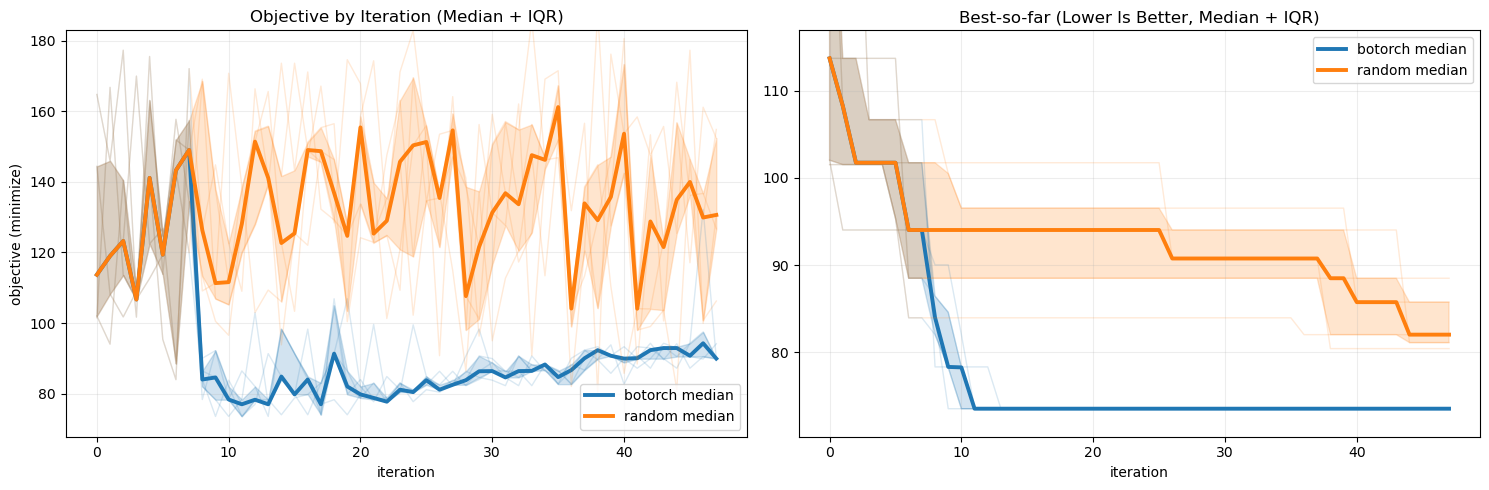

In [8]:
import matplotlib.pyplot as plt

plot_df = history_df.copy()
plot_df = plot_df.sort_values(['optimizer_backend', 'run_id', 'iteration']).reset_index(drop=True)
plot_df = plot_df[np.isfinite(plot_df['objective']) & np.isfinite(plot_df['best_so_far'])]

backend_colors = {
    'botorch': '#1f77b4',
    'random': '#ff7f0e',
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

for backend, bdf in plot_df.groupby('optimizer_backend'):
    color = backend_colors.get(backend, '#666666')

    # faint per-seed/per-run context lines
    for run_id, rdf in bdf.groupby('run_id'):
        axes[0].plot(rdf['iteration'], rdf['objective'], color=color, alpha=0.16, linewidth=1.0)
        axes[1].plot(rdf['iteration'], rdf['best_so_far'], color=color, alpha=0.16, linewidth=1.0)

    agg_obj = bdf.groupby('iteration')['objective'].quantile([0.25, 0.5, 0.75]).unstack()
    agg_best = bdf.groupby('iteration')['best_so_far'].quantile([0.25, 0.5, 0.75]).unstack()

    x_obj = agg_obj.index.to_numpy()
    x_best = agg_best.index.to_numpy()

    axes[0].fill_between(x_obj, agg_obj[0.25].to_numpy(), agg_obj[0.75].to_numpy(), color=color, alpha=0.20)
    axes[0].plot(x_obj, agg_obj[0.5].to_numpy(), color=color, linewidth=2.8, label=f'{backend} median')

    axes[1].fill_between(x_best, agg_best[0.25].to_numpy(), agg_best[0.75].to_numpy(), color=color, alpha=0.20)
    axes[1].plot(x_best, agg_best[0.5].to_numpy(), color=color, linewidth=2.8, label=f'{backend} median')

axes[0].set_title('Objective by Iteration (Median + IQR)')
axes[0].set_xlabel('iteration')
axes[0].set_ylabel('objective (minimize)')
axes[1].set_title('Best-so-far (Lower Is Better, Median + IQR)')
axes[1].set_xlabel('iteration')

# robust y-limits to reduce spike dominance
obj_lo, obj_hi = np.nanquantile(plot_df['objective'], [0.02, 0.98])
best_lo, best_hi = np.nanquantile(plot_df['best_so_far'], [0.02, 0.98])
obj_pad = max(1e-6, 0.08 * (obj_hi - obj_lo))
best_pad = max(1e-6, 0.08 * (best_hi - best_lo))
axes[0].set_ylim(obj_lo - obj_pad, obj_hi + obj_pad)
axes[1].set_ylim(best_lo - best_pad, best_hi + best_pad)

for ax in axes:
    ax.grid(True, alpha=0.22)
    ax.legend(fontsize=10, loc='best')

plt.tight_layout()

# Final-iteration summary metrics
final_rows = []
for run_id, g in plot_df.groupby('run_id'):
    g2 = g.sort_values('iteration')
    final_rows.append({
        'run_id': run_id,
        'optimizer_backend': g2['optimizer_backend'].iloc[-1],
        'final_best_so_far': float(g2['best_so_far'].iloc[-1]),
    })
final_df = pd.DataFrame(final_rows)

summary_backend = final_df.groupby('optimizer_backend')['final_best_so_far'].agg(['median', 'mean', 'count']).reset_index()

bo_vals = final_df.loc[final_df['optimizer_backend'] == 'botorch', 'final_best_so_far'].to_numpy()
rd_vals = final_df.loc[final_df['optimizer_backend'] == 'random', 'final_best_so_far'].to_numpy()
pair_n = int(min(len(bo_vals), len(rd_vals)))
bo_wins = int(np.sum(bo_vals[:pair_n] < rd_vals[:pair_n])) if pair_n > 0 else 0

print(f'paired seeds compared: {pair_n}, bo_wins: {bo_wins}, random_wins: {pair_n - bo_wins}')
display(summary_backend)


best run: bo_replay_general_bo_seed0
best objective: 73.53949221433825
best geometry: [7.7, 8.2, 8.0, 1.1, 0.7, 1.1, 0.13, 0.55]


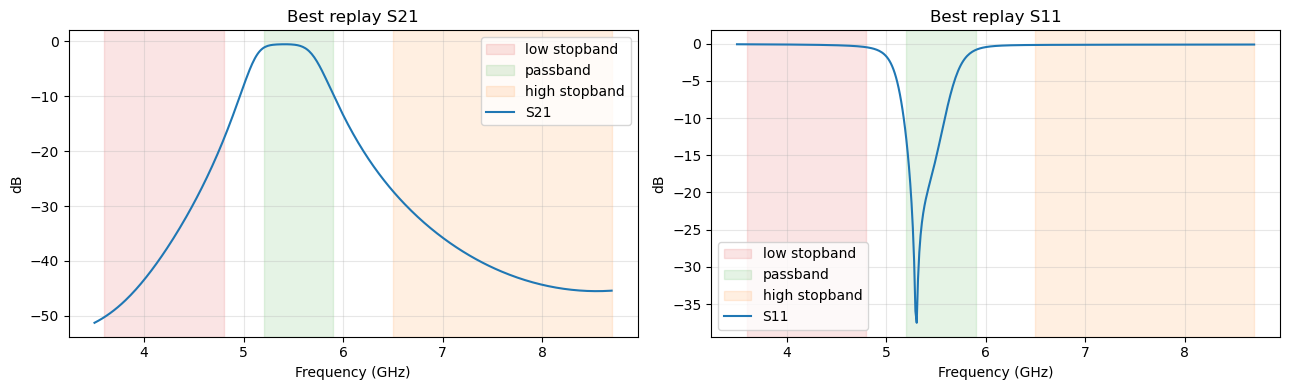

In [9]:
best = min(run_results, key=lambda r: float(r.state.best_objective))
best_trial = best.best_trial
best_geo = np.asarray(best_trial['geometry'], dtype=float)
freqs_best, s_best = dataset.get_response_by_geometry(best_geo)
freqs_ghz = freqs_best / 1e9
s21_db = 20 * np.log10(np.maximum(np.abs(s_best[1, 0, :]), 1e-15))
s11_db = 20 * np.log10(np.maximum(np.abs(s_best[0, 0, :]), 1e-15))

print('best run:', best.run_id)
print('best objective:', best.state.best_objective)
print('best geometry:', best_geo.tolist())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax in axes:
    ax.axvspan(3.6, 4.8, color='tab:red', alpha=0.12, label='low stopband')
    ax.axvspan(5.2, 5.9, color='tab:green', alpha=0.12, label='passband')
    ax.axvspan(6.5, 8.7, color='tab:orange', alpha=0.12, label='high stopband')
    ax.grid(True, alpha=0.3)
axes[0].plot(freqs_ghz, s21_db, label='S21')
axes[0].set_title('Best replay S21')
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('dB')
axes[0].legend()
axes[1].plot(freqs_ghz, s11_db, label='S11')
axes[1].set_title('Best replay S11')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('dB')
axes[1].legend()
plt.tight_layout()
